In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

# Prepare ice flux (q) observation tensor

Create a tensor with columns [x_norm, y_norm, flux_x_scaled, flux_y_scaled]

In [2]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

## Load cleaned thickness point data

In [3]:
# Load thickness points
# NOTE: Outliers are removed from this file.
thickness = pd.read_csv("data/bedmap123_ross_island_cleaned_237k.csv")
thickness.describe()

,lon,lat,x,y,s,t,b,trace_id,t_fa,VX,VY,SPEED
count,237475.000000,237475.000000,237475.000000,2.374750e+05,237475.000000,237475.000000,237475.000000,237475.0,237475.000000,237475.000000,237475.000000,237475.000000
mean,169.789585,-77.951054,232656.784962,-1.292415e+06,-17.162210,213.327455,-230.347498,-9999.0,203.327455,79.544455,-465.039488,492.405705
std,1.755414,0.286735,39273.910941,3.272122e+04,28.433347,86.103862,81.916280,0.0,86.103862,61.871517,307.506106,280.202915
min,166.295032,-78.702596,160101.809997,-1.354850e+06,-9999.000000,-0.000000,-9999.000000,-9999.0,-10.000000,-70.192951,-852.334263,0.700587
25%,168.212057,-78.080027,198093.627159,-1.311885e+06,-23.910000,155.080000,-297.913192,-9999.0,145.080000,39.029352,-739.506093,150.432473
50%,169.757284,-77.931558,232714.850768,-1.290275e+06,-17.317845,207.243674,-225.095585,-9999.0,197.243674,74.715666,-590.389327,596.692086
75%,171.507714,-77.765807,267256.095708,-1.278431e+06,-8.340000,289.010205,-176.830000,-9999.0,279.010205,106.833535,-133.824351,748.742628
max,173.238312,-77.432351,299999.990112,-1.220307e+06,1018.092794,478.949749,545.290000,-9999.0,468.949749,238.314113,61.686919,866.808304


# Generate flux columns from existing columns

In [4]:
# Multiply velocity components by thickness (t_fa) to get flux components
thickness["VX_flux"] = thickness["VX"] * thickness["t_fa"]
thickness["VY_flux"] = thickness["VY"] * thickness["t_fa"]

# If you also want total flux magnitude
thickness["flux_mag"] = np.hypot(thickness["VX_flux"], thickness["VY_flux"])

# Optionally drop rows with NaNs if you want a clean dataset
# Check for NaNs
print(thickness[["VX_flux", "VY_flux", "flux_mag"]].isna().sum())

# Remove so that 240k points remain
thickness = thickness.dropna(subset = ["VX_flux", "VY_flux", "flux_mag"])
print(thickness.shape)

VX_flux     0
VY_flux     0
flux_mag    0
dtype: int64
(237475, 18)


## Load MODIS MOA for visualisation backrgound

In [5]:
modis_ross = torch.load("/Users/kim.bente/DATA/MODIS/MODIS_regional/moa125_2014_hp1_v01_ross_island_with_grid_no_ocean.pt", weights_only = False)

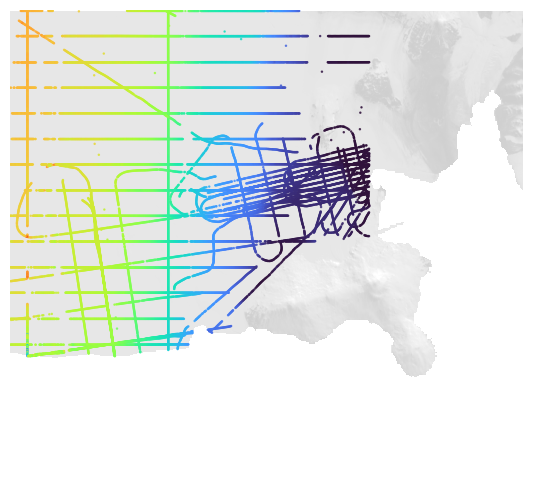

In [6]:
# Use same subsample rate as the ice thickness visualisations
SUBSAMPLE_RATE = 10

fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    # Note: channel at index 3 is no ocean
    modis_ross[3],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

# 2) SMB on top (draw second)
ax.scatter(
    thickness["x"][::SUBSAMPLE_RATE], 
    thickness["y"][::SUBSAMPLE_RATE], 
    c = thickness["flux_mag"][::SUBSAMPLE_RATE], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = "turbo",
    vmin = 0,
    # 400 k worked well
    vmax = 400_000 
    )

ax.set_aspect("equal")
ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

fig.savefig("figures/ice_flux_ross_island.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

### Note: There still is a fair bit of disagreement on the left amongst ice thickness data

## cmap

In [7]:
cmap = "turbo"
dpi = 300

# 1 x N gradient
grad = np.linspace(0, 1, 2048)[None, :]

fig = plt.figure(figsize = (6, 0.6), dpi = dpi)
ax = fig.add_axes([0, 0, 1, 1]) 
ax.imshow(grad, aspect = "auto", cmap = cmap)
ax.set_axis_off()

fig.savefig("figures/cmap/turbo_bar.png", dpi = dpi, transparent = True, bbox_inches = "tight", pad_inches = 0)
plt.close(fig)

# Visualise sparse raw flux vectors - region

(for presentation)

In [8]:
thickness

# 50 x 50 km zoomed in region
x_min_zoom = 200_000
x_max_zoom = 250_000

y_min_zoom = - 1_360_000
y_max_zoom = - 1_310_000

thickness_zoom = thickness[
    (thickness["x"] >= x_min_zoom) &
    (thickness["x"] <= x_max_zoom) &
    (thickness["y"] >= y_min_zoom) &
    (thickness["y"] <= y_max_zoom)
]

thickness_zoom

,lon,lat,x,y,s,t,b,b_inferred,source,trajectory_id,trace_id,t_fa,VX,VY,SPEED,VX_flux,VY_flux,flux_mag
65,171.436700,-77.683500,200003.138625,-1.328213e+06,45.00,271.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,92178,-9999,261.00,151.396129,-740.578684,755.895214,39514.389753,-193291.036535,197288.650972
66,171.439500,-77.662900,200275.129348,-1.330461e+06,45.00,268.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,92179,-9999,258.00,156.795891,-744.146235,760.485746,40453.339916,-191989.728539,196205.322494
67,171.443800,-77.642300,200512.023123,-1.332714e+06,44.00,266.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,92180,-9999,256.00,162.542707,-741.907346,759.504208,41610.932919,-189928.280658,194433.077258
68,171.446600,-77.621600,200785.175936,-1.334973e+06,44.00,264.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,92181,-9999,254.00,164.567817,-745.268131,763.221562,41800.225561,-189298.105172,193858.276786
69,171.456300,-77.599700,200916.669530,-1.337386e+06,44.00,259.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,92182,-9999,249.00,171.916301,-744.698459,764.284639,42807.158933,-185429.916249,190306.875063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
237470,171.567977,-77.443587,200825.331451,-1.354747e+06,-9.90,244.31,-254.21,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,234.31,224.511314,-753.736043,786.462557,52605.246100,-176607.892347,184276.041732
237471,171.567976,-77.443384,200828.626940,-1.354769e+06,-10.67,243.83,-254.49,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,233.83,224.564998,-753.739089,786.480803,52510.033562,-176246.811171,183902.806049
237472,171.567975,-77.443177,200831.986901,-1.354791e+06,-11.05,243.56,-254.61,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,233.56,224.620634,-753.742852,786.500296,52462.395263,-176044.180539,183695.009236
237473,171.567974,-77.442973,200835.298512,-1.354813e+06,-11.32,243.44,-254.77,False,UTIG_2010_ICECAP_AIR_BM3.csv,IR2HI2_2013014_CLH_JKB2h_X18e,-9999,233.44,224.676350,-753.747208,786.520385,52448.447094,-175954.748281,183605.318674


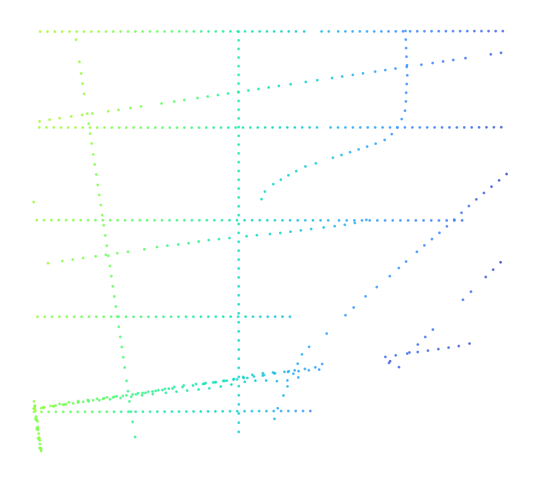

In [9]:
SUBSAMPLE_RATE = 50

fig, ax = plt.subplots(figsize = (8, 6))

# 2) SMB on top (draw second)
ax.scatter(
    thickness_zoom["x"][::SUBSAMPLE_RATE], 
    thickness_zoom["y"][::SUBSAMPLE_RATE], 
    c = thickness_zoom["flux_mag"][::SUBSAMPLE_RATE], 
    s = 1.0, 
    alpha = 0.8, 
    cmap = "turbo",
    vmin = 0,
    # 400 k worked well
    vmax = 400_000 
    )

ax.set_aspect("equal")
ax.set_axis_off()
fig.savefig("figures/ice_flux_ross_island_zoom.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

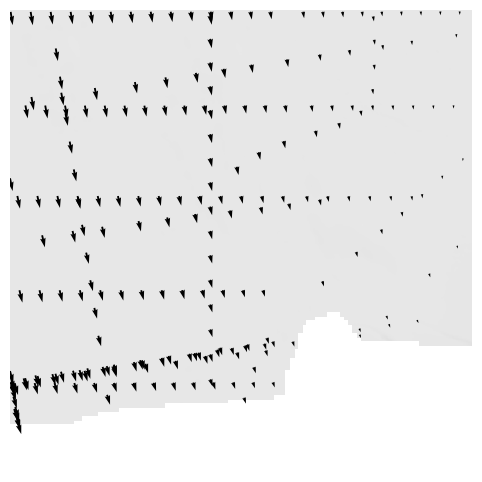

In [10]:
SUBSAMPLE_RATE = 140

fig, ax = plt.subplots(figsize = (8, 6))

ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[3],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

ax.quiver(
    thickness_zoom["x"][::SUBSAMPLE_RATE], 
    thickness_zoom["y"][::SUBSAMPLE_RATE], 
    thickness_zoom["VX_flux"][::SUBSAMPLE_RATE], 
    thickness_zoom["VY_flux"][::SUBSAMPLE_RATE],
    scale = 7_000_000.0,
    # width = 0.005,
)

ax.set_ylim(y_min_zoom, y_max_zoom)
ax.set_xlim(x_min_zoom, x_max_zoom)

ax.set_aspect("equal")
ax.set_axis_off()
fig.savefig("figures/ice_flux_ross_island_zoom.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

## Histogram of flux magnitude

Observation: most values are under 400k.
We thus normalise by 100k.

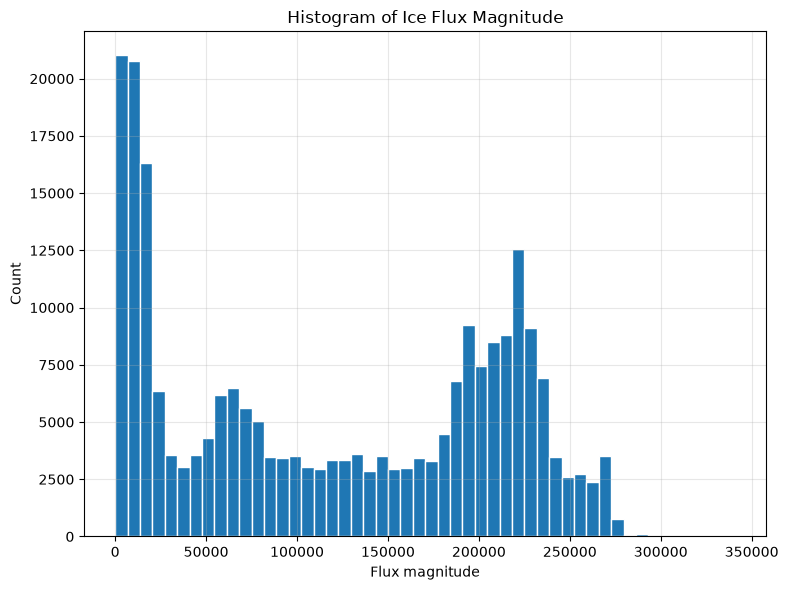

In [11]:
plt.figure(figsize = (8, 6))
plt.hist(thickness["flux_mag"], bins = 50, edgecolor=  "white")
plt.xlabel("Flux magnitude")
plt.ylabel("Count")
plt.title("Histogram of Ice Flux Magnitude")
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

## Affirm normalisation scalar

In [12]:
# Print variance after normalisation
print(np.var(thickness["VX_flux"] / 100_000))
print(np.var(thickness["VY_flux"] / 100_000))

0.024706818858523955
0.8259482953352997


In [13]:
import numpy as np
import scipy.stats

vx = thickness["VX_flux"].to_numpy()
vy = thickness["VY_flux"].to_numpy()
mag = np.hypot(vx, vy)

candidates = {
    "RMS magnitude":      np.sqrt(np.mean(mag**2)),
    "99th pct magnitude": np.percentile(mag, 99),
    "median magnitude":   np.median(mag),
    "pooled std":         np.std(np.concatenate([vx, vy])),
    "max std of VX,VY":   max(vx.std(), vy.std()),
}

print(f"{'method':<20}{'scale':>14}{'std VX':>10}{'std VY':>10}{'max|x|':>10}{'99.9% |x|':>11}")
for name, s in candidates.items():
    nx, ny = vx / s, vy / s
    both = np.abs(np.concatenate([nx, ny]))
    print(f"{name:<20}{s:>14.1f}{nx.std():>10.3f}{ny.std():>10.3f}"
          f"{both.max():>10.2f}{np.percentile(both, 99.9):>11.2f}")

print("\nexcess kurtosis VX, VY:", scipy.stats.kurtosis(vx), scipy.stats.kurtosis(vy))
print("magnitude percentiles (50, 90, 99, 99.9, 100):", np.percentile(mag, [50, 90, 99, 99.9, 100]))

method                       scale    std VX    std VY    max|x|  99.9% |x|
RMS magnitude             148965.5     0.106     0.610      2.28       1.85
99th pct magnitude        270126.8     0.058     0.336      1.26       1.02
median magnitude          116143.1     0.135     0.782      2.92       2.37
pooled std                 92628.8     0.170     0.981      3.66       2.98
max std of VX,VY           90881.7     0.173     1.000      3.73       3.03

excess kurtosis VX, VY: -0.2974751469477077 -1.4996786632930235
magnitude percentiles (50, 90, 99, 99.9, 100): [116143.14371659 230820.35299639 270126.82825    282932.69230622
 340985.40568494]


## Normalise x and y coordinates

### NOTE: It is very important that relative scale is conserved, even if the chosen boundry box is not square.

We determine the larger span (x or y) and we normalise that larger span to (0, 1) and the other accordingly.
One unit n normalised space will represent 200_000 meters in real physical space.

In [21]:
x_span = x_max - x_min
y_span = y_max - y_min

print("Domain span in meters in x-direction:", x_span)
print("Domain span in meters in y-direction:", y_span)

print(np.max([x_span, y_span]))

Domain span in meters in x-direction: 200000
Domain span in meters in y-direction: 180000
200000


In [29]:
# Normalize into [0, 1]
thickness["x_norm"] = (thickness["x"] - x_min) / (x_max - x_min)
# NOTE: Shifted by y_min but SCALED by x_span to keep aspect ratio consistent
thickness["y_norm"] = (thickness["y"] - y_min) / (x_max - x_min)

# Build tensor with x_norm, y_norm, scaled flux
flux_tensor = torch.tensor(
    np.stack([
        thickness["x_norm"].values,
        thickness["y_norm"].values,
        thickness["VX_flux"].values / 100_000,
        thickness["VY_flux"].values / 100_000,
    ], axis = 1),
    dtype = torch.float32
)

print(flux_tensor.shape)
# preview first rows
print(flux_tensor[:5])

torch.Size([237475, 4])
tensor([[ 0.2823,  0.7772,  0.0404, -1.9898],
        [ 0.4140,  0.6460,  0.1000, -1.0539],
        [ 0.4460,  0.6196,  0.0772, -0.6970],
        [ 0.4846,  0.5908,  0.0669, -0.4656],
        [ 0.5229,  0.5743,  0.0666, -0.1828]])


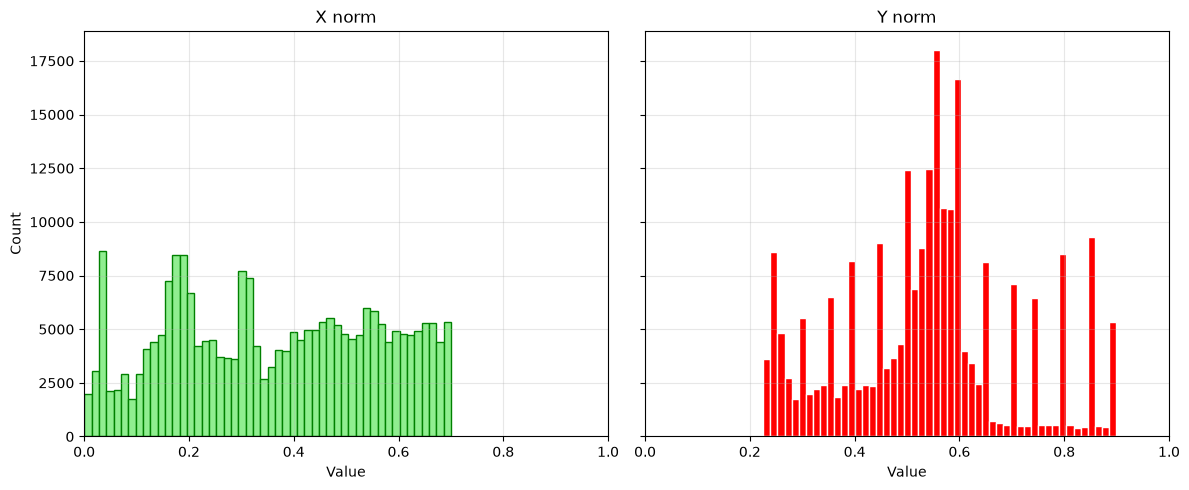

In [32]:
# Plot histograms
# Note: domain and where we have data differs
fig, axes = plt.subplots(1, 2, figsize = (12, 5), sharey = True)

axes[0].hist(thickness["x_norm"], bins = 50, edgecolor = "green", color = "lightgreen")
axes[0].set_title("X norm")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Count")
axes[0].grid(alpha = 0.3)
# fix to show (0, 1) range
axes[0].set_xlim(0, 1)

axes[1].hist(thickness["y_norm"], bins = 50, edgecolor = "white", color = "red")
axes[1].set_title("Y norm")
axes[1].set_xlabel("Value")
axes[1].grid(alpha = 0.3)
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

### Histogram after normalisation

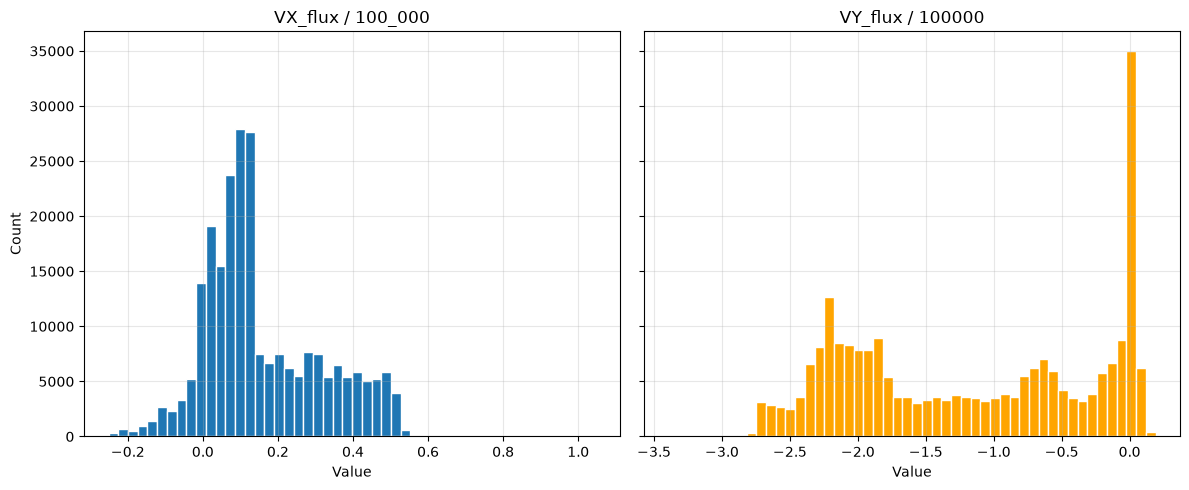

In [33]:
# Extract the last two columns
vx_flux_scaled = flux_tensor[:, 2].numpy()
vy_flux_scaled = flux_tensor[:, 3].numpy()

# Plot histograms
fig, axes = plt.subplots(1, 2, figsize = (12, 5), sharey = True)

axes[0].hist(vx_flux_scaled, bins = 50, edgecolor = "white")
axes[0].set_title("VX_flux / 100_000")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Count")
axes[0].grid(alpha = 0.3)

axes[1].hist(vy_flux_scaled, bins = 50, edgecolor = "white", color = "orange")
axes[1].set_title("VY_flux / 100000")
axes[1].set_xlabel("Value")
axes[1].grid(alpha = 0.3)

plt.tight_layout()
plt.show()

# Export tensor with all flux observations

In [34]:
torch.save(flux_tensor, "data/flux_tensor.pt")